<a href="https://colab.research.google.com/github/2007ethanz/nfl-trajectory-forecasting/blob/main/notebooks/nfl_trajectory_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### *Base LSTM Model (Attention of other players had not been added)

In [55]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

import kagglehub
path = kagglehub.competition_download('nfl-big-data-bowl-2026-prediction')
print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction


In [56]:
import os
for root, dirs, files in os.walk(path):
    for f in sorted(files):
        full = os.path.join(root, f)
        print(f"{os.path.getsize(full)/1e6:8.1f} MB  {full}")

     0.2 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/test.csv
     8.5 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/test_input.csv
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/__init__.py
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/nfl_gateway.py
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/nfl_inference_server.py
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/core/__init__.py
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/core/base_gateway.py
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kaggle_evaluation/core/kaggle_evaluation.proto
     0.0 MB  /root/.cache/kagglehub/competitions/nfl-big-data-bowl-2026-prediction/kag

In [57]:
import pandas as pd, os
train_dir = os.path.join(path, "train")

inp = pd.read_csv(os.path.join(train_dir, "input_2023_w01.csv"))
out = pd.read_csv(os.path.join(train_dir, "output_2023_w01.csv"))

print(inp.shape, out.shape)
print(inp.columns.tolist())
print(out.columns.tolist())
inp.head()

(285714, 23) (32088, 6)
['game_id', 'play_id', 'player_to_predict', 'nfl_id', 'frame_id', 'play_direction', 'absolute_yardline_number', 'player_name', 'player_height', 'player_weight', 'player_birth_date', 'player_position', 'player_side', 'player_role', 'x', 'y', 's', 'a', 'dir', 'o', 'num_frames_output', 'ball_land_x', 'ball_land_y']
['game_id', 'play_id', 'nfl_id', 'frame_id', 'x', 'y']


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,...,player_role,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y
0,2023090700,101,False,54527,1,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.94,0.09,0.39,322.40,238.24,21,63.259998,-0.22
1,2023090700,101,False,54527,2,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.94,0.04,0.61,200.89,236.05,21,63.259998,-0.22
2,2023090700,101,False,54527,3,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.33,36.93,0.12,0.73,147.55,240.60,21,63.259998,-0.22
3,2023090700,101,False,54527,4,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.35,36.92,0.23,0.81,131.40,244.25,21,63.259998,-0.22
4,2023090700,101,False,54527,5,right,42,Bryan Cook,6-1,210,...,Defensive Coverage,52.37,36.90,0.35,0.82,123.26,244.25,21,63.259998,-0.22


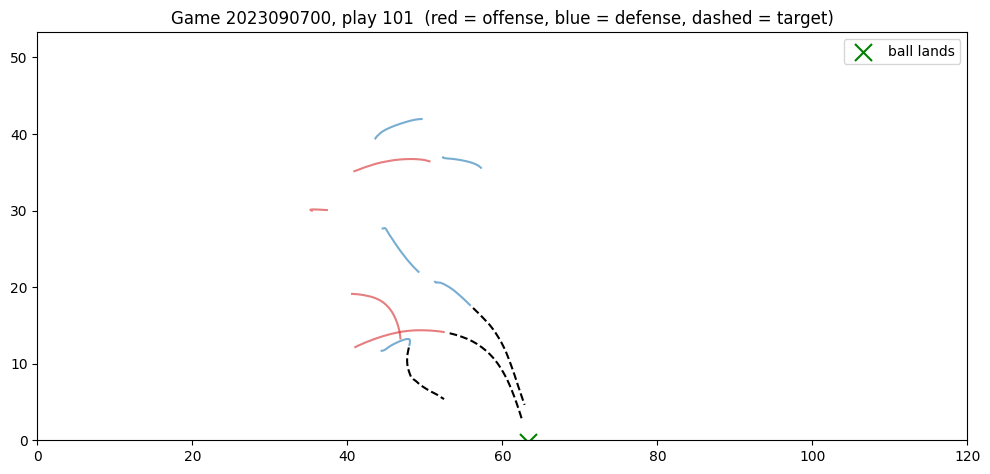

In [58]:
import matplotlib.pyplot as plt

g, p = inp[["game_id", "play_id"]].iloc[0]          # pick the first play
before = inp[(inp.game_id == g) & (inp.play_id == p)]
after  = out[(out.game_id == g) & (out.play_id == p)]

fig, ax = plt.subplots(figsize=(12, 5.3))
for pid, d in before.groupby("nfl_id"):
    color = "tab:red" if d.player_side.iloc[0] == "Offense" else "tab:blue"
    ax.plot(d.x, d.y, color=color, alpha=0.6)                 # path before throw
for pid, d in after.groupby("nfl_id"):
    ax.plot(d.x, d.y, color="black", linestyle="--")          # path while ball in air

ax.scatter(before.ball_land_x.iloc[0], before.ball_land_y.iloc[0],
           marker="x", s=150, color="green", label="ball lands")
ax.set_xlim(0, 120); ax.set_ylim(0, 53.3)
ax.set_title(f"Game {g}, play {p}  (red = offense, blue = defense, dashed = target)")
ax.legend(); plt.show()

In [59]:
import pandas as pd, numpy as np, os, glob

train_dir = os.path.join(path, "train")

def load_weeks(weeks):
    inp = pd.concat([pd.read_csv(f"{train_dir}/input_2023_w{w:02d}.csv").assign(week=w) for w in weeks])
    out = pd.concat([pd.read_csv(f"{train_dir}/output_2023_w{w:02d}.csv").assign(week=w) for w in weeks])
    return inp, out

inp_all, out_all = load_weeks(range(1, 19))
print(inp_all.shape, out_all.shape)

(4880579, 24) (562936, 7)


In [60]:
def flip_left_plays(inp, out):
    inp, out = inp.copy(), out.copy()
    left = inp.play_direction == "left"
    inp.loc[left, "x"] = 120 - inp.loc[left, "x"]
    inp.loc[left, "y"] = 53.3 - inp.loc[left, "y"]
    inp.loc[left, "ball_land_x"] = 120 - inp.loc[left, "ball_land_x"]
    inp.loc[left, "ball_land_y"] = 53.3 - inp.loc[left, "ball_land_y"]
    inp.loc[left, "dir"] = (inp.loc[left, "dir"] + 180) % 360
    inp.loc[left, "o"]   = (inp.loc[left, "o"] + 180) % 360

    # outputs don't have play_direction, so look it up from the inputs
    dirs = inp[["game_id", "play_id", "play_direction"]].drop_duplicates()
    out = out.merge(dirs, on=["game_id", "play_id"], how="left")
    left_o = out.play_direction == "left"
    out.loc[left_o, "x"] = 120 - out.loc[left_o, "x"]
    out.loc[left_o, "y"] = 53.3 - out.loc[left_o, "y"]
    return inp, out

inp_all, out_all = flip_left_plays(inp_all, out_all)

In [61]:
TRAIN_WEEKS, VAL_WEEKS, TEST_WEEKS = range(1, 15), [15, 16], [17, 18]

def split(df, weeks): return df[df.week.isin(weeks)]

In [62]:
KEYS = ["game_id", "play_id", "nfl_id"]

def baseline_predict(inp, out):
    last2 = inp.sort_values("frame_id").groupby(KEYS).tail(2)
    last  = last2.groupby(KEYS).tail(1).set_index(KEYS)[["x", "y"]]
    prev  = last2.groupby(KEYS).head(1).set_index(KEYS)[["x", "y"]]
    vel   = last - prev

    o = out.join(last, on=KEYS, rsuffix="_last").join(vel, on=KEYS, rsuffix="_vel")
    o["x_pred"] = o.x_last + o.frame_id * o.x_vel
    o["y_pred"] = o.y_last + o.frame_id * o.y_vel
    return o

def rmse(o):
    return np.sqrt((((o.x - o.x_pred)**2 + (o.y - o.y_pred)**2) / 2).mean())

base_test = baseline_predict(split(inp_all, TEST_WEEKS), split(out_all, TEST_WEEKS))
print(f"Baseline RMSE on test weeks 17–18: {rmse(base_test):.3f} yards")

Baseline RMSE on test weeks 17–18: 1.706 yards


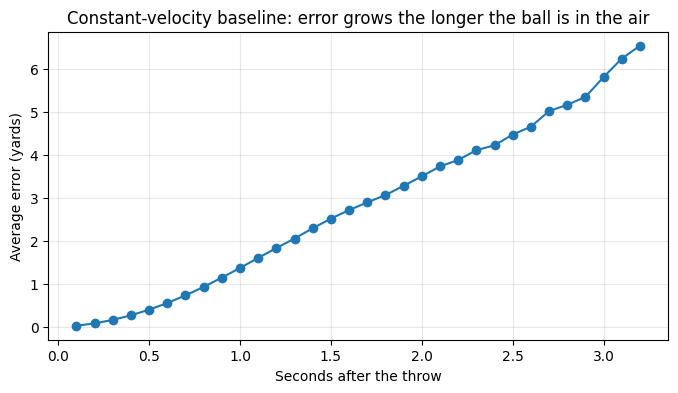

In [63]:
import matplotlib.pyplot as plt

base_test["err"] = np.sqrt(((base_test.x - base_test.x_pred)**2 + (base_test.y - base_test.y_pred)**2) / 2)
by_frame = base_test.groupby("frame_id").err.mean()

plt.figure(figsize=(8, 4))
plt.plot(by_frame.index / 10, by_frame.values, marker="o")
plt.xlabel("Seconds after the throw"); plt.ylabel("Average error (yards)")
plt.title("Constant-velocity baseline: error grows the longer the ball is in the air")
plt.grid(alpha=0.3); plt.show()

In [64]:
T_IN = 10   # frames of history (1 second)
FEATS = ["x", "y", "s", "a", "sin_dir", "cos_dir",
         "ball_dx", "ball_dy", "is_defense", "is_target"]

def add_features(inp):
    inp = inp.copy()
    r = np.radians(inp.dir)
    inp["sin_dir"], inp["cos_dir"] = np.sin(r), np.cos(r)
    inp["ball_dx"] = inp.ball_land_x - inp.x          # how far from where the ball lands
    inp["ball_dy"] = inp.ball_land_y - inp.y
    inp["is_defense"] = (inp.player_side == "Defense").astype(float)
    inp["is_target"]  = (inp.player_role == "Targeted Receiver").astype(float)
    return inp

inp_all = add_features(inp_all)

In [65]:
T_OUT = int(out_all.groupby(KEYS).size().max())    # longest flight, in frames
print("T_OUT =", T_OUT)

def build_dataset(inp, out):
    inp = inp[inp.player_to_predict].sort_values(KEYS + ["frame_id"])
    out = out.sort_values(KEYS + ["frame_id"])
    targets = {k: g[["x", "y"]].values for k, g in out.groupby(KEYS)}

    X, Y, M, START = [], [], [], []
    for k, g in inp.groupby(KEYS):
        if k not in targets:
            continue
        f = g[FEATS].values[-T_IN:]
        if len(f) < T_IN:                                   # pad short histories
            f = np.vstack([np.repeat(f[:1], T_IN - len(f), 0), f])

        start = g[["x", "y"]].values[-1]                    # position at the throw
        moves = np.diff(np.vstack([start, targets[k]]), axis=0)   # per-frame movement
        n = len(moves)

        y = np.zeros((T_OUT, 2)); y[:n] = moves
        m = np.zeros(T_OUT);      m[:n] = 1
        X.append(f); Y.append(y); M.append(m); START.append(start)

    return [np.array(a, dtype=np.float32) for a in (X, Y, M, START)]

Xtr, Ytr, Mtr, Str = build_dataset(split(inp_all, TRAIN_WEEKS), split(out_all, TRAIN_WEEKS))
Xva, Yva, Mva, Sva = build_dataset(split(inp_all, VAL_WEEKS),   split(out_all, VAL_WEEKS))
Xte, Yte, Mte, Ste = build_dataset(split(inp_all, TEST_WEEKS),  split(out_all, TEST_WEEKS))
print(Xtr.shape, Ytr.shape, Xva.shape, Xte.shape)

T_OUT = 94
(35467, 10, 10) (35467, 94, 2) (5540, 10, 10) (5038, 10, 10)


In [66]:
mu  = Xtr.reshape(-1, len(FEATS)).mean(0)
std = Xtr.reshape(-1, len(FEATS)).std(0) + 1e-6
Xtr, Xva, Xte = [(a - mu) / std for a in (Xtr, Xva, Xte)]

In [67]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using", device)

def loader(X, Y, M, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(Y), torch.tensor(M))
    return DataLoader(ds, batch_size=256, shuffle=shuffle)

train_dl = loader(Xtr, Ytr, Mtr, True)
val_dl   = loader(Xva, Yva, Mva, False)
test_dl  = loader(Xte, Yte, Mte, False)

Using cuda


In [68]:
class Seq2Seq(nn.Module):
    def __init__(self, n_feats, hidden=128):
        super().__init__()
        self.encoder = nn.LSTM(n_feats, hidden, batch_first=True)   # reads the 10 pre-throw frames
        self.decoder = nn.LSTMCell(2, hidden)                       # predicts one frame at a time
        self.out = nn.Linear(hidden, 2)                             # → (dx, dy) movement

    def forward(self, x, n_steps):
        _, (h, c) = self.encoder(x)            # summary of how the player has been moving
        h, c = h[0], c[0]
        step = torch.zeros(x.size(0), 2, device=x.device)
        moves = []
        for _ in range(n_steps):
            h, c = self.decoder(step, (h, c))
            step = self.out(h)                 # predicted movement this frame
            moves.append(step)                 # fed back in as the next input
        return torch.stack(moves, dim=1)

model = Seq2Seq(len(FEATS)).to(device)

In [69]:
def position_sq_error(pred_moves, true_moves, mask):
    n = pred_moves.size(1)
    pred_pos = pred_moves.cumsum(1)                 # add up movements → positions
    true_pos = true_moves[:, :n].cumsum(1)          # (relative to the throw position)
    m = mask[:, :n]
    se = ((pred_pos - true_pos) ** 2).sum(-1) / 2   # same /2 as the competition RMSE
    return (se * m).sum(), m.sum()

def run_epoch(dl, train):
    model.train(train)
    total_se, total_n = 0.0, 0.0
    for X, Y, M in dl:
        X, Y, M = X.to(device), Y.to(device), M.to(device)
        n_steps = int(M.sum(1).max())               # only predict as far as this batch needs
        with torch.set_grad_enabled(train):
            pred = model(X, n_steps)
            se, n = position_sq_error(pred, Y, M)
            if train:
                opt.zero_grad()
                (se / n).backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
        total_se += se.item(); total_n += n.item()
    return (total_se / total_n) ** 0.5             # RMSE in yards

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
best, patience, bad = float("inf"), 5, 0

for epoch in range(1, 41):
    tr = run_epoch(train_dl, True)
    va = run_epoch(val_dl, False)
    print(f"epoch {epoch:2d} | train RMSE {tr:.3f} | val RMSE {va:.3f}")
    if va < best:
        best, bad = va, 0
        torch.save(model.state_dict(), "best_lstm.pt")   # keep the best version
    else:
        bad += 1
        if bad >= patience:
            print("Early stopping"); break

epoch  1 | train RMSE 2.128 | val RMSE 1.443
epoch  2 | train RMSE 1.381 | val RMSE 1.173
epoch  3 | train RMSE 1.240 | val RMSE 1.027
epoch  4 | train RMSE 1.165 | val RMSE 0.963
epoch  5 | train RMSE 0.985 | val RMSE 1.006
epoch  6 | train RMSE 0.944 | val RMSE 0.963
epoch  7 | train RMSE 0.905 | val RMSE 0.898
epoch  8 | train RMSE 0.833 | val RMSE 0.888
epoch  9 | train RMSE 0.832 | val RMSE 0.882
epoch 10 | train RMSE 0.829 | val RMSE 0.891
epoch 11 | train RMSE 0.772 | val RMSE 0.851
epoch 12 | train RMSE 0.774 | val RMSE 0.829
epoch 13 | train RMSE 0.753 | val RMSE 0.831
epoch 14 | train RMSE 0.755 | val RMSE 0.806
epoch 15 | train RMSE 0.741 | val RMSE 0.823
epoch 16 | train RMSE 0.725 | val RMSE 0.797
epoch 17 | train RMSE 0.717 | val RMSE 0.825
epoch 18 | train RMSE 0.719 | val RMSE 0.775
epoch 19 | train RMSE 0.712 | val RMSE 0.836
epoch 20 | train RMSE 0.689 | val RMSE 0.798
epoch 21 | train RMSE 0.683 | val RMSE 0.788
epoch 22 | train RMSE 0.685 | val RMSE 0.823
epoch 23 |

In [70]:
model.load_state_dict(torch.load("best_lstm.pt"))
test_rmse = run_epoch(test_dl, False)
print(f"LSTM test RMSE:     {test_rmse:.3f} yards")
print(f"Baseline test RMSE: 1.706 yards")
print(f"Improvement:        {(1 - test_rmse / 1.706) * 100:.1f}%")

LSTM test RMSE:     0.708 yards
Baseline test RMSE: 1.706 yards
Improvement:        58.5%


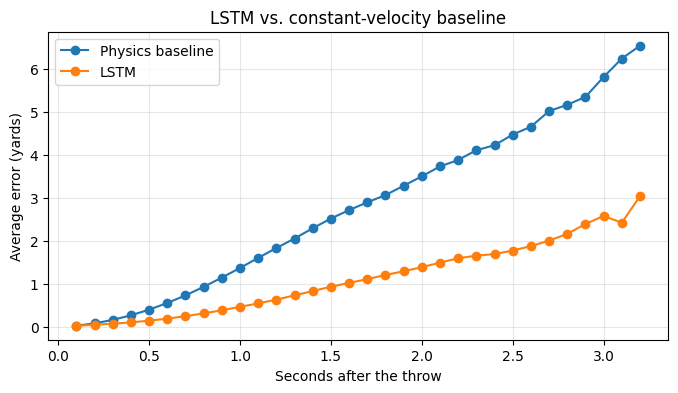

In [71]:
model.eval()
err_sum, counts = np.zeros(T_OUT), np.zeros(T_OUT)
with torch.no_grad():
    for X, Y, M in test_dl:
        X, Y, M = X.to(device), Y.to(device), M.to(device)
        n = int(M.sum(1).max())
        pred_pos = model(X, n).cumsum(1)
        true_pos = Y[:, :n].cumsum(1)
        e = ((((pred_pos - true_pos) ** 2).sum(-1) / 2).sqrt() * M[:, :n])
        err_sum[:n] += e.sum(0).cpu().numpy()
        counts[:n]  += M[:, :n].sum(0).cpu().numpy()
lstm_by_frame = err_sum / np.maximum(counts, 1)

frames = by_frame.index.values                          # baseline curve from Cell 5
plt.figure(figsize=(8, 4))
plt.plot(frames / 10, by_frame.values, marker="o", label="Physics baseline")
plt.plot(frames / 10, lstm_by_frame[frames - 1], marker="o", label="LSTM")
plt.xlabel("Seconds after the throw"); plt.ylabel("Average error (yards)")
plt.title("LSTM vs. constant-velocity baseline")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### **Animated Example**

In [72]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

test_inp = split(inp_all, TEST_WEEKS)
test_out = split(out_all, TEST_WEEKS)

def predict_play(g, p):
    pin  = test_inp[(test_inp.game_id == g) & (test_inp.play_id == p)].sort_values(KEYS + ["frame_id"])
    pout = test_out[(test_out.game_id == g) & (test_out.play_id == p)].sort_values(KEYS + ["frame_id"])
    preds = {}
    model.eval()
    for nid, d in pin[pin.player_to_predict].groupby("nfl_id"):
        true = pout[pout.nfl_id == nid][["x", "y"]].values
        if len(true) == 0:
            continue
        f = d[FEATS].values[-T_IN:]
        if len(f) < T_IN:
            f = np.vstack([np.repeat(f[:1], T_IN - len(f), 0), f])
        x = torch.tensor(((f - mu) / std)[None], dtype=torch.float32, device=device)
        with torch.no_grad():
            moves = model(x, len(true))[0].cpu().numpy()

        start, prev = d[["x", "y"]].values[-1], d[["x", "y"]].values[-2]
        k = np.arange(1, len(true) + 1)[:, None]
        preds[nid] = dict(
            start=start,
            true=true,
            lstm=start + moves.cumsum(0),
            base=start + k * (start - prev),
            defense=(d.player_side.iloc[0] == "Defense"),
        )
    return pin, preds

In [73]:
def animate_play(g, p, fname="play.gif"):
    pin, preds = predict_play(g, p)
    n = max(len(v["true"]) for v in preds.values())
    path = lambda v, key, k: np.vstack([v["start"], v[key][:k]])   # connect to throw position

    fig, ax = plt.subplots(figsize=(10, 5))
    for _, d in pin.groupby("nfl_id"):                             # faint pre-throw routes
        c = "tab:blue" if d.player_side.iloc[0] == "Defense" else "tab:red"
        ax.plot(d.x, d.y, color=c, alpha=0.12)
    ax.scatter(pin.ball_land_x.iloc[0], pin.ball_land_y.iloc[0],
               marker="x", s=150, color="green", zorder=7)

    artists = {}
    for nid, v in preds.items():
        c = "tab:blue" if v["defense"] else "tab:red"
        artists[nid] = dict(
            true=ax.plot([], [], color=c, lw=4, alpha=0.9, zorder=3)[0],         # thick, solid
            lstm=ax.plot([], [], color="black", ls="--", lw=1.5, zorder=5)[0],    # thin, on top
            base=ax.plot([], [], color="tab:orange", ls="-.", lw=2, zorder=4)[0],
            dot=ax.plot([], [], "o", color=c, ms=9, zorder=6)[0],
        )

    # zoom in around the action
    pts = np.vstack([pin[["x", "y"]].values] + [np.vstack([v["true"], v["lstm"], v["base"]]) for v in preds.values()])
    ax.set_xlim(pts[:, 0].min() - 5, pts[:, 0].max() + 5)
    ax.set_ylim(max(pts[:, 1].min() - 5, 0), min(pts[:, 1].max() + 5, 53.3))
    ax.set_aspect("equal")

    ax.plot([], [], color="tab:red", lw=4, label="actual (offense)")
    ax.plot([], [], color="tab:blue", lw=4, label="actual (defense)")
    ax.plot([], [], color="black", ls="--", lw=1.5, label="LSTM")
    ax.plot([], [], color="tab:orange", ls="-.", lw=2, label="physics baseline")
    ax.scatter([], [], marker="x", color="green", label="ball lands")
    ax.legend(loc="upper left", fontsize=9)

    def update(i):
        for nid, v in preds.items():
            k = min(i + 1, len(v["true"]))
            a = artists[nid]
            for key in ("true", "lstm", "base"):
                pth = path(v, key, k)
                a[key].set_data(pth[:, 0], pth[:, 1])
            a["dot"].set_data([v["true"][k - 1, 0]], [v["true"][k - 1, 1]])
        ax.set_title(f"Game {g}, play {p}   |   {(i + 1) / 10:.1f}s after the throw")
        return []

    ani = FuncAnimation(fig, update, frames=n, interval=100)
    ani.save(fname, writer=PillowWriter(fps=10))
    plt.close(fig)
    display(Image(fname))

56 candidate plays


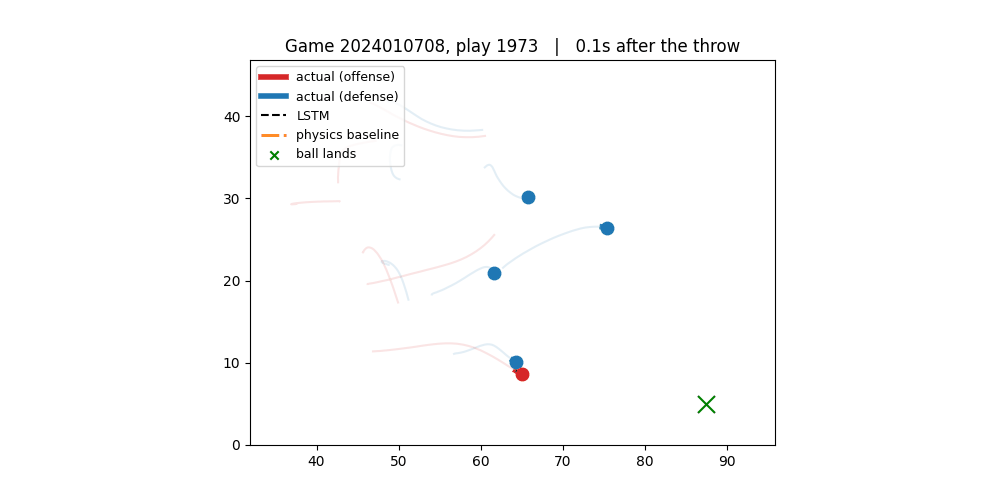

In [74]:
# plays with a longer flight (≥2.5s) and at least 3 players to predict look best
cand = (test_inp[test_inp.player_to_predict]
        .groupby(["game_id", "play_id"])
        .agg(n=("num_frames_output", "first"), k=("nfl_id", "nunique")))
cand = cand[(cand.n >= 25) & (cand.k >= 3)]
print(len(cand), "candidate plays")

g, p = cand.sample(1, random_state=0).index[0]
animate_play(g, p)

### **Adding Attention of other players**

In [75]:
def build_play_dataset(inp, out):
    inp = inp.sort_values(KEYS + ["frame_id"])
    out = out.sort_values(KEYS + ["frame_id"])
    targets = {k: g[["x", "y"]].values for k, g in out.groupby(KEYS)}

    plays = []
    for (g, p), dp in inp.groupby(["game_id", "play_id"]):
        Xp, Yp, Mp, Dp = [], [], [], []
        for nid, d in dp.groupby("nfl_id"):
            f = d[FEATS].values[-T_IN:]
            if len(f) < T_IN:
                f = np.vstack([np.repeat(f[:1], T_IN - len(f), 0), f])
            y, m = np.zeros((T_OUT, 2)), np.zeros(T_OUT)
            key = (g, p, nid)
            if d.player_to_predict.iloc[0] and key in targets:        # only scored players get targets
                start = d[["x", "y"]].values[-1]
                moves = np.diff(np.vstack([start, targets[key]]), axis=0)
                y[:len(moves)], m[:len(moves)] = moves, 1
            Xp.append((f - mu) / std)                                  # same normalization as before
            Yp.append(y); Mp.append(m)
            Dp.append(d.player_side.iloc[0] == "Defense")
        plays.append((np.array(Xp), np.array(Yp), np.array(Mp), np.array(Dp)))
    return plays

def pad_plays(plays, P):
    N = len(plays)
    X  = np.zeros((N, P, T_IN, len(FEATS)), np.float32)
    Y  = np.zeros((N, P, T_OUT, 2), np.float32)
    M  = np.zeros((N, P, T_OUT), np.float32)
    D  = np.zeros((N, P), bool)
    PAD = np.ones((N, P), bool)                                        # True = empty player slot
    for i, (x, y, m, d) in enumerate(plays):
        n = len(x)
        X[i, :n], Y[i, :n], M[i, :n], D[i, :n], PAD[i, :n] = x, y, m, d, False
    return X, Y, M, D, PAD

plays_tr = build_play_dataset(split(inp_all, TRAIN_WEEKS), split(out_all, TRAIN_WEEKS))
plays_va = build_play_dataset(split(inp_all, VAL_WEEKS),   split(out_all, VAL_WEEKS))
plays_te = build_play_dataset(split(inp_all, TEST_WEEKS),  split(out_all, TEST_WEEKS))

P_MAX = max(len(pl[0]) for pl in plays_tr + plays_va + plays_te)
print("plays:", len(plays_tr), len(plays_va), len(plays_te), "| max players per play:", P_MAX)

Ptr, Pva, Pte = (pad_plays(pl, P_MAX) for pl in (plays_tr, plays_va, plays_te))

plays: 10862 1687 1559 | max players per play: 17


In [76]:
class AttnSeq2Seq(nn.Module):
    def __init__(self, n_feats, hidden=128, heads=4):
        super().__init__()
        self.encoder = nn.LSTM(n_feats, hidden, batch_first=True)
        self.attn = nn.TransformerEncoderLayer(d_model=hidden, nhead=heads,
                                               dim_feedforward=256, dropout=0.1,
                                               batch_first=True)          # players attend to players
        self.decoder = nn.LSTMCell(2, hidden)
        self.out = nn.Linear(hidden, 2)

    def forward(self, x, pad, sel, n_steps):
        B, P, T, F = x.shape
        _, (h, c) = self.encoder(x.reshape(B * P, T, F))   # 1. each player's movement summary
        h = h[0].reshape(B, P, -1)
        c = c[0].reshape(B, P, -1)

        h = self.attn(h, src_key_padding_mask=pad)          # 2. NEW: mix in info from other players

        h, c = h[sel], c[sel]                               # 3. decode only the scored players
        step = torch.zeros(h.size(0), 2, device=x.device)
        moves = []
        for _ in range(n_steps):
            h, c = self.decoder(step, (h, c))
            step = self.out(h)
            moves.append(step)
        return torch.stack(moves, dim=1)

attn_model = AttnSeq2Seq(len(FEATS)).to(device)

In [77]:
def play_loader(P, shuffle):
    X, Y, M, D, PAD = P
    ds = TensorDataset(*(torch.tensor(a) for a in (X, Y, M, D, PAD)))
    return DataLoader(ds, batch_size=64, shuffle=shuffle)

ptrain_dl, pval_dl, ptest_dl = play_loader(Ptr, True), play_loader(Pva, False), play_loader(Pte, False)

def run_attn_epoch(dl, train):
    attn_model.train(train)
    total_se, total_n = 0.0, 0.0
    for X, Y, M, D, PAD in dl:
        X, Y, M, PAD = X.to(device), Y.to(device), M.to(device), PAD.to(device)
        sel = M.sum(-1) > 0                                   # scored players
        Ys, Ms = Y[sel], M[sel]
        n_steps = int(Ms.sum(1).max())
        with torch.set_grad_enabled(train):
            pred = attn_model(X, PAD, sel, n_steps)
            se, n = position_sq_error(pred, Ys, Ms)
            if train:
                attn_opt.zero_grad()
                (se / n).backward()
                nn.utils.clip_grad_norm_(attn_model.parameters(), 1.0)
                attn_opt.step()
        total_se += se.item(); total_n += n.item()
    return (total_se / total_n) ** 0.5

attn_opt = torch.optim.Adam(attn_model.parameters(), lr=1e-3)
best, patience, bad = float("inf"), 5, 0
for epoch in range(1, 41):
    tr = run_attn_epoch(ptrain_dl, True)
    va = run_attn_epoch(pval_dl, False)
    print(f"epoch {epoch:2d} | train RMSE {tr:.3f} | val RMSE {va:.3f}")
    if va < best:
        best, bad = va, 0
        torch.save(attn_model.state_dict(), "best_attn.pt")
    else:
        bad += 1
        if bad >= patience:
            print("Early stopping"); break

epoch  1 | train RMSE 1.828 | val RMSE 1.292
epoch  2 | train RMSE 1.364 | val RMSE 1.131
epoch  3 | train RMSE 1.249 | val RMSE 1.061
epoch  4 | train RMSE 1.267 | val RMSE 1.120
epoch  5 | train RMSE 1.161 | val RMSE 0.938
epoch  6 | train RMSE 1.066 | val RMSE 0.954
epoch  7 | train RMSE 0.928 | val RMSE 0.907
epoch  8 | train RMSE 0.904 | val RMSE 0.907
epoch  9 | train RMSE 0.984 | val RMSE 0.865
epoch 10 | train RMSE 0.828 | val RMSE 0.915
epoch 11 | train RMSE 0.865 | val RMSE 0.791
epoch 12 | train RMSE 0.807 | val RMSE 0.798
epoch 13 | train RMSE 0.816 | val RMSE 0.812
epoch 14 | train RMSE 0.826 | val RMSE 0.879
epoch 15 | train RMSE 0.807 | val RMSE 0.774
epoch 16 | train RMSE 0.742 | val RMSE 0.762
epoch 17 | train RMSE 0.785 | val RMSE 0.824
epoch 18 | train RMSE 0.728 | val RMSE 0.769
epoch 19 | train RMSE 0.672 | val RMSE 0.740
epoch 20 | train RMSE 0.669 | val RMSE 0.808
epoch 21 | train RMSE 0.666 | val RMSE 0.748
epoch 22 | train RMSE 0.664 | val RMSE 0.766
epoch 23 |

In [ ]:
attn_model.load_state_dict(torch.load("best_attn.pt"))
model.load_state_dict(torch.load("best_lstm.pt"))
attn_model.eval(); model.eval()

stats = {name: {"all": [0, 0], "offense": [0, 0], "defense": [0, 0]} for name in ("LSTM", "LSTM + attention")}

with torch.no_grad():
    for X, Y, M, D, PAD in ptest_dl:
        X, Y, M, D, PAD = X.to(device), Y.to(device), M.to(device), D.to(device), PAD.to(device)
        sel = M.sum(-1) > 0
        Ys, Ms, Ds = Y[sel], M[sel], D[sel]
        n = int(Ms.sum(1).max())
        preds = {"LSTM": model(X[sel], n),
                 "LSTM + attention": attn_model(X, PAD, sel, n)}
        for name, pred in preds.items():
            se = ((pred.cumsum(1) - Ys[:, :n].cumsum(1)) ** 2).sum(-1) / 2 * Ms[:, :n]
            for group, rows in (("all", slice(None)), ("offense", ~Ds), ("defense", Ds)):
                stats[name][group][0] += se[rows].sum().item()
                stats[name][group][1] += Ms[:, :n][rows].sum().item()

print(f"{'':18s}{'all':>8s}{'offense':>10s}{'defense':>10s}")
for name, s in stats.items():
    row = [ (s[g][0] / s[g][1]) ** 0.5 for g in ("all", "offense", "defense") ]
    print(f"{name:18s}" + "".join(f"{r:10.3f}" for r in row))
print("Physics baseline (all): 1.706")

### **Validation of findings**

In [79]:
import random, pandas as pd, os
from google.colab import drive
drive.mount("/content/drive")
SAVE = "/content/drive/MyDrive/nfl-project"
os.makedirs(SAVE, exist_ok=True)
CSV = f"{SAVE}/seed_results.csv"

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def lstm_epoch(m, opt, dl, train):
    m.train(train); se_sum, n_sum = 0.0, 0.0
    for X, Y, M in dl:
        X, Y, M = X.to(device), Y.to(device), M.to(device)
        n = int(M.sum(1).max())
        with torch.set_grad_enabled(train):
            se, cnt = position_sq_error(m(X, n), Y, M)
            if train:
                opt.zero_grad(); (se / cnt).backward()
                nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        se_sum += se.item(); n_sum += cnt.item()
    return (se_sum / n_sum) ** 0.5

def attn_epoch(m, opt, dl, train):
    m.train(train); se_sum, n_sum = 0.0, 0.0
    for X, Y, M, D, PAD in dl:
        X, Y, M, PAD = X.to(device), Y.to(device), M.to(device), PAD.to(device)
        sel = M.sum(-1) > 0
        Ys, Ms = Y[sel], M[sel]
        n = int(Ms.sum(1).max())
        with torch.set_grad_enabled(train):
            se, cnt = position_sq_error(m(X, PAD, sel, n), Ys, Ms)
            if train:
                opt.zero_grad(); (se / cnt).backward()
                nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        se_sum += se.item(); n_sum += cnt.item()
    return (se_sum / n_sum) ** 0.5

def fit(m, epoch_fn, tr_dl, va_dl, path, max_epochs=60, patience=8):
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    best, bad = float("inf"), 0
    for ep in range(1, max_epochs + 1):
        epoch_fn(m, opt, tr_dl, True)
        va = epoch_fn(m, None, va_dl, False)
        sched.step(va)
        if va < best:
            best, bad = va, 0; torch.save(m.state_dict(), path)
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(torch.load(path))
    print(f"   {os.path.basename(path)}: best val {best:.3f} after {ep} epochs")
    return m

def evaluate(lstm_m, attn_m):
    lstm_m.eval(); attn_m.eval()
    acc = {k: {g: [0, 0] for g in ("all", "offense", "defense")} for k in ("LSTM", "LSTM + attention")}
    with torch.no_grad():
        for X, Y, M, D, PAD in ptest_dl:
            X, Y, M, D, PAD = (t.to(device) for t in (X, Y, M, D, PAD))
            sel = M.sum(-1) > 0
            Ys, Ms, Ds = Y[sel], M[sel], D[sel]
            n = int(Ms.sum(1).max())
            for name, pred in (("LSTM", lstm_m(X[sel], n)),
                               ("LSTM + attention", attn_m(X, PAD, sel, n))):
                se = ((pred.cumsum(1) - Ys[:, :n].cumsum(1)) ** 2).sum(-1) / 2 * Ms[:, :n]
                for g, rows in (("all", slice(None)), ("offense", ~Ds), ("defense", Ds)):
                    acc[name][g][0] += se[rows].sum().item()
                    acc[name][g][1] += Ms[:, :n][rows].sum().item()
    return {name: {g: (v[0] / v[1]) ** 0.5 for g, v in d.items()} for name, d in acc.items()}

# ---- resumable seed loop ----
results = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
done = {r["seed"] for r in results}
print("Already finished seeds:", sorted(done))

SEEDS = [0, 1, 2]          # ← change to [1], then [2] on later runs
for seed in SEEDS:
    if seed in done:
        print(f"Seed {seed} already done, skipping"); continue
    print(f"Seed {seed}")
    set_seed(seed)
    lstm_m = fit(Seq2Seq(len(FEATS)).to(device), lstm_epoch, train_dl, val_dl, f"{SAVE}/lstm_s{seed}.pt")
    set_seed(seed)
    attn_m = fit(AttnSeq2Seq(len(FEATS)).to(device), attn_epoch, ptrain_dl, pval_dl, f"{SAVE}/attn_s{seed}.pt")
    for name, groups in evaluate(lstm_m, attn_m).items():
        results.append({"seed": seed, "model": name, **groups})
    pd.DataFrame(results).to_csv(CSV, index=False)      # saved to Drive right away
    print(f"Seed {seed} saved to Drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already finished seeds: []
Seed 0
   lstm_s0.pt: best val 0.724 after 55 epochs
   attn_s0.pt: best val 0.654 after 50 epochs
Seed 0 saved to Drive
Seed 1
   lstm_s1.pt: best val 0.720 after 42 epochs
   attn_s1.pt: best val 0.679 after 52 epochs
Seed 1 saved to Drive
Seed 2
   lstm_s2.pt: best val 0.736 after 33 epochs
   attn_s2.pt: best val 0.684 after 41 epochs
Seed 2 saved to Drive


In [80]:
res = pd.read_csv(CSV)
print("Per seed:"); print(res.round(3).to_string(index=False))

summary = res.groupby("model")[["all", "offense", "defense"]].agg(["mean", "std"]).round(3)
print("\nMean ± std across seeds:"); print(summary)

l = res[res.model == "LSTM"].set_index("seed")
a = res[res.model == "LSTM + attention"].set_index("seed")
imp = ((1 - a[["all", "offense", "defense"]] / l[["all", "offense", "defense"]]) * 100).round(1)
print("\nAttention improvement per seed (%):"); print(imp)

Per seed:
 seed            model   all  offense  defense
    0             LSTM 0.669    0.413    0.747
    0 LSTM + attention 0.633    0.412    0.702
    1             LSTM 0.656    0.398    0.735
    1 LSTM + attention 0.635    0.436    0.698
    2             LSTM 0.671    0.439    0.745
    2 LSTM + attention 0.615    0.391    0.685

Mean ± std across seeds:
                    all        offense        defense       
                   mean    std    mean    std    mean    std
model                                                       
LSTM              0.665  0.008   0.417  0.021   0.742  0.006
LSTM + attention  0.628  0.011   0.413  0.023   0.695  0.009

Attention improvement per seed (%):
      all  offense  defense
seed                       
0     5.4      0.1      6.1
1     3.3     -9.5      4.9
2     8.3     10.9      8.0


### **Attetion-Weight Visualization**

In [81]:
import matplotlib.pyplot as plt

# raw test-week data for drawing (reload if it was freed earlier)
try:
    test_inp = split(inp_all, TEST_WEEKS)
except NameError:
    _i, _o = load_weeks(TEST_WEEKS)
    _i, _o = flip_left_plays(_i, _o)
    test_inp = add_features(_i)

def play_tensor(g, p):
    """One play as model input: (1, P_MAX, T_IN, F) plus info about each player."""
    dp = test_inp[(test_inp.game_id == g) & (test_inp.play_id == p)].sort_values(KEYS + ["frame_id"])
    X = np.zeros((1, P_MAX, T_IN, len(FEATS)), np.float32)
    PAD = np.ones((1, P_MAX), bool)
    info = []
    for i, (nid, d) in enumerate(dp.groupby("nfl_id")):
        f = d[FEATS].values[-T_IN:]
        if len(f) < T_IN:
            f = np.vstack([np.repeat(f[:1], T_IN - len(f), 0), f])
        X[0, i], PAD[0, i] = (f - mu) / std, False
        info.append(dict(nfl_id=nid, name=d.player_name.iloc[0], pos=d.player_position.iloc[0],
                         side=d.player_side.iloc[0], role=d.player_role.iloc[0],
                         predict=bool(d.player_to_predict.iloc[0]),
                         x=d.x.values[-1], y=d.y.values[-1], route=d[["x", "y"]].values))
    return torch.tensor(X, device=device), torch.tensor(PAD, device=device), info, dp

def attention_weights(model, X, PAD):
    """(P, P) matrix: row i = how much player i attends to each player j."""
    model.eval()
    with torch.no_grad():
        B, P, T, F = X.shape
        _, (h, _) = model.encoder(X.reshape(B * P, T, F))
        h = h[0].reshape(B, P, -1)
        _, w = model.attn.self_attn(h, h, h, key_padding_mask=PAD,
                                    need_weights=True, average_attn_weights=True)
    return w[0].cpu().numpy()

viz_model = AttnSeq2Seq(len(FEATS)).to(device)
viz_model.load_state_dict(torch.load(f"{SAVE}/attn_s2.pt"))

<All keys matched successfully>

/tmp/ipykernel_771/882793302.py:54: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: (d.player_role == "Targeted Receiver").any()


1423 usable test plays


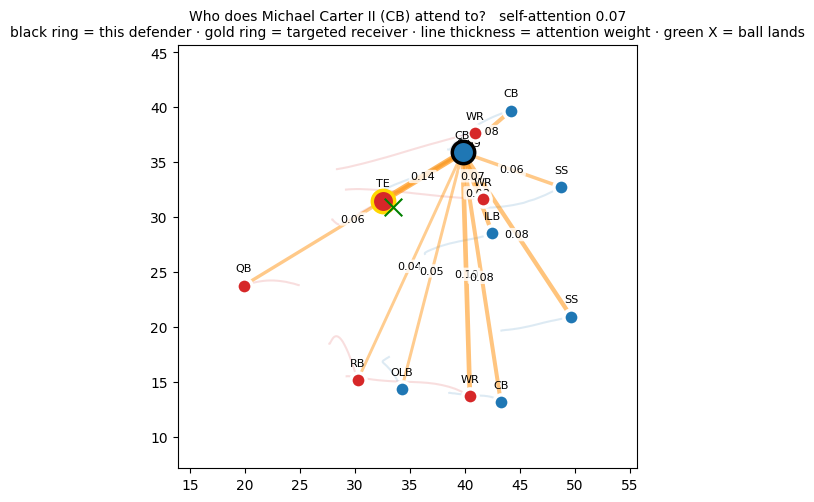

 0.14   TE  Offense  David Njoku  ← targeted receiver
 0.10   WR  Offense  Elijah Moore
 0.09   WR  Offense  David Bell
 0.08   SS  Defense  Jordan Whitehead
 0.08  ILB  Defense  C.J. Mosley
 0.08   CB  Defense  D.J. Reed
 0.08   CB  Defense  Sauce Gardner
 0.07   WR  Offense  Cedric Tillman
 0.07   CB  Defense  Michael Carter II
 0.06   SS  Defense  Tony Adams
 0.06   QB  Offense  Joe Flacco
 0.05  OLB  Defense  Quincy Williams
 0.04   RB  Offense  Kareem Hunt


In [84]:
def plot_attention(g, p, defender_idx=None):
    X, PAD, info, dp = play_tensor(g, p)
    W = attention_weights(viz_model, X, PAD)
    n = len(info)

    # default: the scored defender closest to the targeted receiver
    tgt = next(i for i, d in enumerate(info) if d["role"] == "Targeted Receiver")
    if defender_idx is None:
        cands = [i for i, d in enumerate(info) if d["side"] == "Defense" and d["predict"]]
        defender_idx = min(cands, key=lambda i: (info[i]["x"] - info[tgt]["x"])**2 + (info[i]["y"] - info[tgt]["y"])**2)
    d0 = info[defender_idx]

    fig, ax = plt.subplots(figsize=(11, 5.5))
    for d in info:                                                    # faint pre-throw routes
        ax.plot(d["route"][:, 0], d["route"][:, 1],
                color="tab:blue" if d["side"] == "Defense" else "tab:red", alpha=0.15)

    for j in range(n):                                                # attention lines
        if j == defender_idx:
            continue
        w = W[defender_idx, j]
        ax.plot([d0["x"], info[j]["x"]], [d0["y"], info[j]["y"]],
                color="darkorange", lw=1 + 25 * w, alpha=0.35 + 0.65 * min(1, w * 3), zorder=2)
        mx, my = (d0["x"] + info[j]["x"]) / 2, (d0["y"] + info[j]["y"]) / 2
        ax.text(mx, my, f"{w:.2f}", fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)

    for i, d in enumerate(info):                                      # players
        color = "tab:blue" if d["side"] == "Defense" else "tab:red"
        size = 260 if i in (defender_idx, tgt) else 120
        edge = "black" if i == defender_idx else ("gold" if i == tgt else "white")
        ax.scatter(d["x"], d["y"], s=size, color=color, edgecolor=edge, linewidth=2.5, zorder=5)
        ax.text(d["x"], d["y"] + 1.3, d["pos"], fontsize=8, ha="center", zorder=6)

    ax.scatter(dp.ball_land_x.iloc[0], dp.ball_land_y.iloc[0], marker="x", s=160, color="green", zorder=6)

    xs, ys = [d["x"] for d in info], [d["y"] for d in info]
    ax.set_xlim(min(xs + [dp.ball_land_x.iloc[0]]) - 6, max(xs + [dp.ball_land_x.iloc[0]]) + 6)
    ax.set_ylim(max(0, min(ys) - 6), min(53.3, max(ys) + 6))
    ax.set_aspect("equal")
    ax.set_title(f"Who does {d0['name']} ({d0['pos']}) attend to?   "
                 f"self-attention {W[defender_idx, defender_idx]:.2f}\n"
                 f"black ring = this defender · gold ring = targeted receiver · "
                 f"line thickness = attention weight · green X = ball lands", fontsize=10)
    plt.show()

    ranked = sorted(((W[defender_idx, j], info[j]) for j in range(n)), key=lambda t: -t[0])
    for w, d in ranked:
        tag = "  ← targeted receiver" if d["role"] == "Targeted Receiver" else ""
        print(f"{w:5.2f}  {d['pos']:>3}  {d['side']:<8} {d['name']}{tag}")

# plays with a targeted receiver and at least one scored defender
plays_ok = (test_inp.groupby(["game_id", "play_id"])
            .apply(lambda d: (d.player_role == "Targeted Receiver").any()
                             and ((d.player_side == "Defense") & d.player_to_predict).any()))
plays_ok = plays_ok[plays_ok].index.tolist()
print(len(plays_ok), "usable test plays")

g, p = plays_ok[0]
plot_attention(g, p)

In [86]:
def target_attention_stats(model):
    share, uniform, top1 = [], [], []
    for g, p in plays_ok:
        X, PAD, info, _ = play_tensor(g, p)
        W = attention_weights(model, X, PAD)
        n = len(info)
        tgt = next(i for i, d in enumerate(info) if d["role"] == "Targeted Receiver")
        for i, d in enumerate(info):
            if d["side"] == "Defense" and d["predict"]:
                others = [j for j in range(n) if j != i]
                share.append(W[i, tgt])
                uniform.append(1 / n)                                   # what "no preference" would give
                top1.append(max(others, key=lambda j: W[i, j]) == tgt)  # is the receiver his #1 focus?
    return np.mean(share), np.mean(uniform), np.mean(top1)

for s in [0, 1, 2]:
    m = AttnSeq2Seq(len(FEATS)).to(device)
    m.load_state_dict(torch.load(f"{SAVE}/attn_s{s}.pt"))
    sh, un, t1 = target_attention_stats(m)
    print(f"seed {s}: defenders give the targeted receiver {sh:.2f} of their attention "
          f"(no-preference baseline {un:.2f}, {sh/un:.1f}x) | receiver is their #1 focus {t1:.0%} of the time")

seed 0: defenders give the targeted receiver 0.14 of their attention (no-preference baseline 0.08, 1.6x) | receiver is their #1 focus 40% of the time
seed 1: defenders give the targeted receiver 0.14 of their attention (no-preference baseline 0.08, 1.6x) | receiver is their #1 focus 44% of the time
seed 2: defenders give the targeted receiver 0.14 of their attention (no-preference baseline 0.08, 1.7x) | receiver is their #1 focus 47% of the time


### **Example Plays**

In [87]:
import os
GIF_DIR = f"{SAVE}/gifs"
os.makedirs(GIF_DIR, exist_ok=True)

try:
    test_out = split(out_all, TEST_WEEKS)
except NameError:
    _i, _o = load_weeks(TEST_WEEKS)
    _i, test_out = flip_left_plays(_i, _o)

attn_best = AttnSeq2Seq(len(FEATS)).to(device); attn_best.load_state_dict(torch.load(f"{SAVE}/attn_s2.pt")); attn_best.eval()
lstm_best = Seq2Seq(len(FEATS)).to(device);     lstm_best.load_state_dict(torch.load(f"{SAVE}/lstm_s2.pt")); lstm_best.eval()

out_groups = {k: g.sort_values("frame_id")[["x", "y"]].values for k, g in test_out.groupby(KEYS)}

def predict_play_all(g, p):
    """Actual, attention, LSTM, and physics paths for every scored player on one play."""
    X, PAD, info, dp = play_tensor(g, p)
    idx = [i for i, d in enumerate(info) if d["predict"] and (g, p, d["nfl_id"]) in out_groups]
    if not idx:
        return None, None
    n = max(len(out_groups[(g, p, info[i]["nfl_id"])]) for i in idx)
    sel = torch.zeros((1, P_MAX), dtype=torch.bool, device=device); sel[0, idx] = True
    with torch.no_grad():
        attn_moves = attn_best(X, PAD, sel, n).cpu().numpy()
        lstm_moves = lstm_best(X[0, idx], n).cpu().numpy()

    preds = {}
    for r, i in enumerate(idx):
        d = info[i]
        true = out_groups[(g, p, d["nfl_id"])]
        k = len(true)
        start, prev = d["route"][-1], d["route"][-2]
        preds[d["nfl_id"]] = dict(
            start=start, true=true, defense=(d["side"] == "Defense"), pos=d["pos"],
            attn=start + attn_moves[r, :k].cumsum(0),
            lstm=start + lstm_moves[r, :k].cumsum(0),
            base=start + np.arange(1, k + 1)[:, None] * (start - prev),
        )
    return preds, dp

def play_rmse(preds, key):
    se = np.concatenate([((v[key] - v["true"]) ** 2).sum(1) / 2 for v in preds.values()])
    return float(np.sqrt(se.mean()))

rows = []
all_plays = test_inp[["game_id", "play_id"]].drop_duplicates().itertuples(index=False)
for g, p in all_plays:
    preds, dp = predict_play_all(g, p)
    if preds is None:
        continue
    rows.append(dict(game_id=g, play_id=p,
                     frames=max(len(v["true"]) for v in preds.values()),
                     n_players=len(preds),
                     base=play_rmse(preds, "base"),
                     lstm=play_rmse(preds, "lstm"),
                     attn=play_rmse(preds, "attn")))
scores = pd.DataFrame(rows)
print(len(scores), "plays scored")
print(scores[["base", "lstm", "attn"]].describe().round(3))

1559 plays scored
           base      lstm      attn
count  1559.000  1559.000  1559.000
mean      1.002     0.353     0.313
std       0.763     0.305     0.286
min       0.013     0.019     0.021
25%       0.463     0.160     0.135
50%       0.749     0.252     0.217
75%       1.334     0.430     0.379
max       5.002     2.832     2.540


In [94]:
# ===== Cell G2 (replace the old one): football-field GIFs =====
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.animation import FuncAnimation, PillowWriter

# ---- colors (chosen to read well on green) ----
OFF, DEF = "#2D6BFF", "#E3262E"          # offense blue, defense red
MODEL, BASE, LSTM = "#FFE14D", "white", "#FF8CF0"
VIEW_W = 60                               # every GIF shows the same 60-yard window, full field width

def outline(w):
    return [pe.Stroke(linewidth=w, foreground="black", alpha=0.75), pe.Normal()]

def draw_field(ax, x0):
    """Green field with yard lines, hash marks and numbers. Plays run left → right."""
    x1 = x0 + VIEW_W
    for s in range(0, 120, 5):                                   # mowing stripes
        ax.axvspan(s, s + 5, color="#3C8D40" if (s // 5) % 2 else "#358538", zorder=0, lw=0)
    ax.axvspan(0, 10, color="#2A6E31", zorder=0, lw=0)           # end zones
    ax.axvspan(110, 120, color="#2A6E31", zorder=0, lw=0)
    for x in range(10, 111, 5):                                  # yard lines
        ax.plot([x, x], [0, 53.3], color="white", lw=3 if x in (10, 110) else 1.4, alpha=0.85, zorder=1)
    for x in range(11, 110):                                     # hash marks
        if x % 5:
            for y in (0.4, 17.8, 35.5, 52.9):
                ax.plot([x, x], [y - 0.35, y + 0.35], color="white", lw=1, alpha=0.7, zorder=1)
    for x in range(20, 101, 10):                                 # yard numbers
        num = x - 10 if x <= 60 else 110 - x
        for y, rot in ((9, 0), (44.3, 180)):
            ax.text(x, y, str(num), color="white", fontsize=17, fontweight="bold",
                    ha="center", va="center", rotation=rot, alpha=0.8, zorder=1)
    ax.set_xlim(x0, x1)
    ax.set_ylim(0, 53.3)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color("white"); sp.set_linewidth(2)

def view_start(pts):
    """Left edge of the fixed window, centred on the action."""
    cx = (pts[:, 0].min() + pts[:, 0].max()) / 2
    return float(np.clip(cx - VIEW_W / 2, 0, 120 - VIEW_W))

def render(preds, routes, ball, rmse, fname, title, show_lstm=False, extra_frames=10):
    """preds: {id: dict(start, true, attn, base, lstm, defense)}; routes: [(xy_array, is_defense)]."""
    n = max(len(v["true"]) for v in preds.values())
    keys = ["true", "attn", "base"] + (["lstm"] if show_lstm else [])
    pts = np.vstack([r for r, _ in routes] + [np.vstack([v[k] for k in keys]) for v in preds.values()] + [np.array([ball])])

    fig = plt.figure(figsize=(9, 9.6), dpi=90)
    ax = fig.add_axes([0.03, 0.15, 0.94, 0.77])
    draw_field(ax, view_start(pts))

    for xy, is_def in routes:                                       # pre-throw routes
        ax.plot(xy[:, 0], xy[:, 1], color=DEF if is_def else OFF, lw=2.6, alpha=0.4, zorder=2,
                solid_capstyle="round")
    ax.scatter(*ball, marker="X", s=260, color="white", edgecolor="black", linewidth=1.5, zorder=9)

    style = {"attn": dict(color=MODEL, ls=(0, (4, 2.5)), lw=2.6, zorder=6, path_effects=outline(4.2)),
             "base": dict(color=BASE, ls="-.", lw=2.2, zorder=5, alpha=0.95),
             "lstm": dict(color=LSTM, ls=":", lw=2.6, zorder=5, path_effects=outline(4))}
    art = {}
    for nid, v in preds.items():
        c = DEF if v["defense"] else OFF
        a = {"true": ax.plot([], [], color=c, lw=4.5, solid_capstyle="round", zorder=4, path_effects=outline(6.5))[0],
             "dot": ax.plot([], [], "o", color=c, ms=12, mec="white", mew=2, zorder=8)[0]}
        for k in keys[1:]:
            a[k] = ax.plot([], [], **style[k])[0]
        art[nid] = a

    handles = [plt.Line2D([], [], color=OFF, lw=4.5, label="actual – offense"),
               plt.Line2D([], [], color=DEF, lw=4.5, label="actual – defense"),
               plt.Line2D([], [], color=MODEL, ls=(0, (4, 2.5)), lw=2.6, path_effects=outline(4.2),
                          label=f"LSTM + attention  ({rmse['attn']:.2f} yd)")]
    if show_lstm:
        handles.append(plt.Line2D([], [], color=LSTM, ls=":", lw=2.6, path_effects=outline(4),
                                  label=f"LSTM only  ({rmse['lstm']:.2f} yd)"))
    handles += [plt.Line2D([], [], color="0.35", ls="-.", lw=2.2, label=f"physics baseline  ({rmse['base']:.2f} yd)"),
                plt.Line2D([], [], marker="X", ls="", ms=12, color="white", mec="black", label="ball lands")]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10, frameon=False,
               bbox_to_anchor=(0.5, 0.01), handlelength=3)
    head = fig.text(0.5, 0.955, "", ha="center", va="center", fontsize=14, fontweight="bold")

    path = lambda v, k, i: np.vstack([v["start"], v[k][:i]])
    def update(f):
        for nid, v in preds.items():
            i = min(f + 1, len(v["true"]))
            for k in keys:
                p = path(v, k, i)
                art[nid][k].set_data(p[:, 0], p[:, 1])
            art[nid]["dot"].set_data([v["true"][i - 1, 0]], [v["true"][i - 1, 1]])
        head.set_text(f"{title}   ·   {min(f + 1, n) / 10:.1f}s after the throw")
        return []

    ani = FuncAnimation(fig, update, frames=n + extra_frames, interval=100)
    ani.save(fname, writer=PillowWriter(fps=10))
    update(n + extra_frames - 1)
    fig.savefig(fname.replace(".gif", "_final.png"), dpi=150)   # still frame for the poster
    plt.close(fig)

from IPython.display import Image, display

def animate_play(g, p, fname, title_tag="", show_lstm=False):
    preds, dp = predict_play_all(g, p)                      # from Cell G1
    routes = [(d[["x", "y"]].values, d.player_side.iloc[0] == "Defense") for _, d in dp.groupby("nfl_id")]
    ball = (dp.ball_land_x.iloc[0], dp.ball_land_y.iloc[0])
    rmse = {k: play_rmse(preds, k) for k in ("base", "lstm", "attn")}
    render(preds, routes, ball, rmse, fname, title_tag, show_lstm=show_lstm)
    display(Image(fname))
    print(f"saved {fname} (+ _final.png still)  |  physics {rmse['base']:.2f}  LSTM {rmse['lstm']:.2f}  attention {rmse['attn']:.2f}")

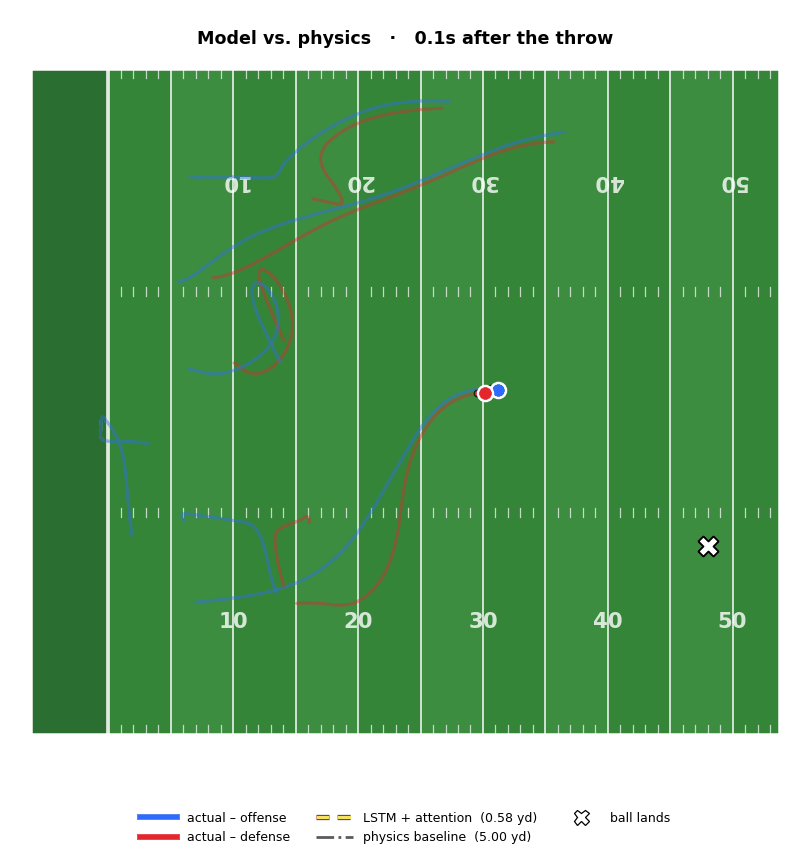

saved /content/drive/MyDrive/nfl-project/gifs/1_big_win.gif (+ _final.png still)  |  physics 5.00  LSTM 0.86  attention 0.58


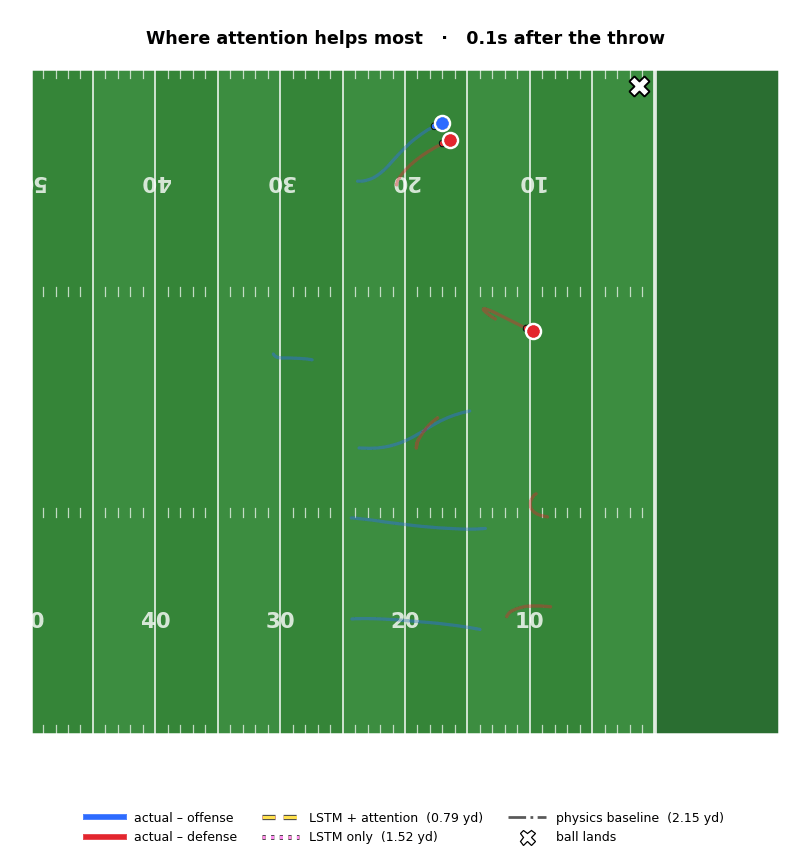

saved /content/drive/MyDrive/nfl-project/gifs/2_attention_helps.gif (+ _final.png still)  |  physics 2.15  LSTM 1.52  attention 0.79


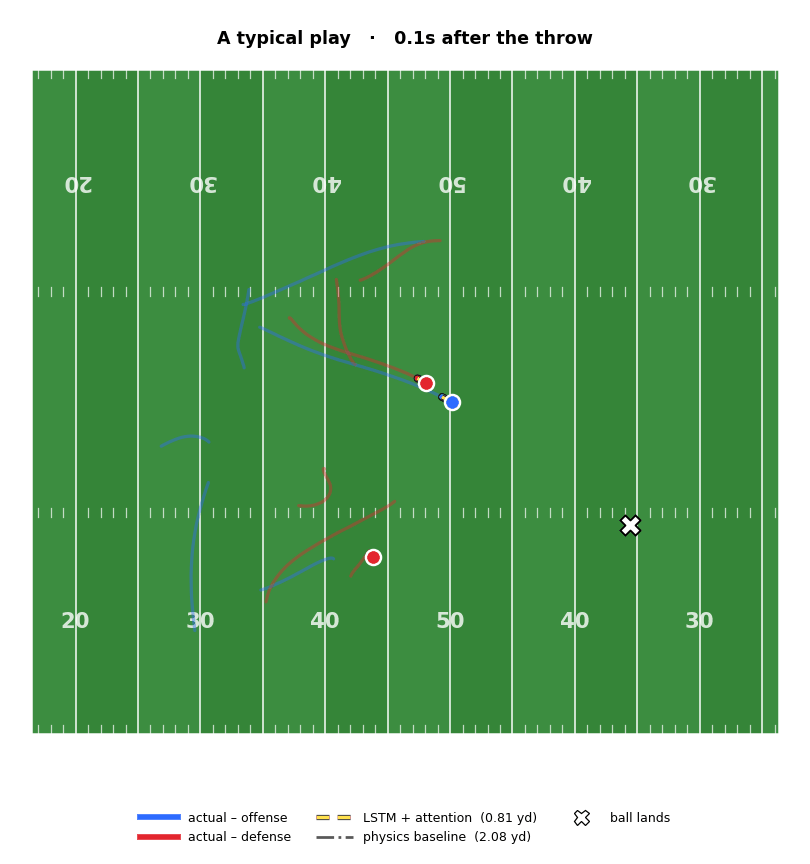

saved /content/drive/MyDrive/nfl-project/gifs/3_typical.gif (+ _final.png still)  |  physics 2.08  LSTM 0.93  attention 0.81


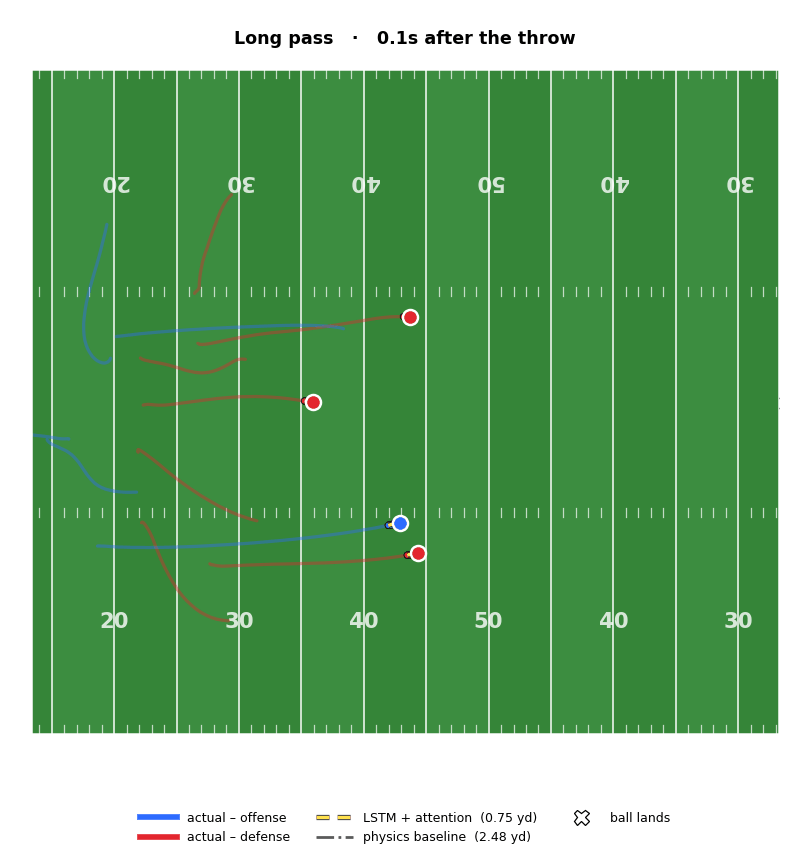

saved /content/drive/MyDrive/nfl-project/gifs/4_long_pass.gif (+ _final.png still)  |  physics 2.48  LSTM 0.87  attention 0.75


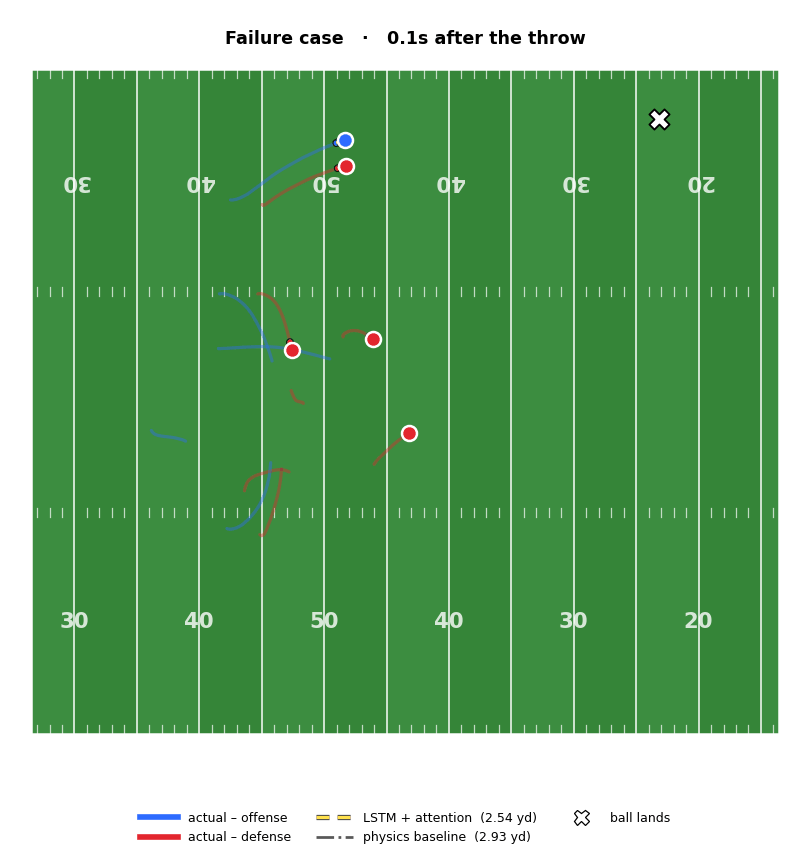

saved /content/drive/MyDrive/nfl-project/gifs/5_failure_case.gif (+ _final.png still)  |  physics 2.93  LSTM 2.83  attention 2.54


In [95]:
s = scores[(scores.frames >= 20) & (scores.n_players >= 2)].copy()   # long enough to see movement
s["win_vs_physics"] = s.base - s.attn
s["win_vs_lstm"]    = s.lstm - s.attn

picks = {
    "1_big_win":         s.sort_values("win_vs_physics", ascending=False).iloc[0],
    "2_attention_helps": s.sort_values("win_vs_lstm",    ascending=False).iloc[0],
    "3_typical":         s.iloc[(s.attn - s.attn.median()).abs().argsort().iloc[0]],
    "4_long_pass":       s[s.attn < s.attn.median()].sort_values("frames", ascending=False).iloc[0],
    "5_failure_case":    s.sort_values("attn", ascending=False).iloc[0],
}
titles = {
    "1_big_win": "Model vs. physics",
    "2_attention_helps": "Where attention helps most",
    "3_typical": "A typical play",
    "4_long_pass": "Long pass",
    "5_failure_case": "Failure case",
}

for name, row in picks.items():
    g, p = int(row.game_id), int(row.play_id)
    animate_play(g, p, f"{GIF_DIR}/{name}.gif", title_tag=titles[name],
                 show_lstm=(name == "2_attention_helps"))